# Thực hành Chương 4 – Tổng hợp tiếng nói (TTS)
## Notebook theo roadmap trong `Chương 4.pdf`, liên hệ Chương 14 của *Spoken Language Processing*

**Mục tiêu:** đi lần lượt từ văn bản thô → phân tích văn bản/ngữ âm → mô hình hóa ngữ điệu → sinh tiếng nói → đánh giá.

> **Phạm vi:** đây là một baseline học tập chạy được, không phải bản tái tạo toàn bộ Festival hay một hệ TTS nghiên cứu. Các bước chuẩn hóa, tách câu, POS, tra từ điển và đánh giá được minh họa bằng code. G2P/ngữ điệu chỉ là baseline đơn giản; bộ tổng hợp âm thanh dùng gTTS (cần Internet), không tự cài đặt Klatt, unit-selection, HMM-TTS, Tacotron 2 hoặc HiFi-GAN.

## 0. Cài đặt thư viện

Chạy cell dưới trong môi trường notebook. Nếu môi trường đã có thư viện thì có thể bỏ qua. `nltk` dùng cho tokenization/POS; `cmudict` là từ điển phát âm tiếng Anh; `gTTS` tạo audio qua dịch vụ trực tuyến.

In [1]:
%pip install -q nltk cmudict gTTS soundfile librosa matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
typer 0.25.1 requires click>=8.2.1, but you have click 8.1.8 which is incompatible.
wandb 0.27.0 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Khởi tạo và tải tài nguyên NLP

Chương 14 phân tách **Text Analysis Module (TAM)** và **Phonetic Analysis Module (PAM)**. Ta giữ riêng các hàm theo chức năng để dễ kiểm thử/thay thế.

In [2]:
import re
import json
import math
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
for resource in ("punkt", "punkt_tab", "averaged_perceptron_tagger",
                 "averaged_perceptron_tagger_eng", "cmudict"):
    try:
        nltk.download(resource, quiet=True)
    except Exception as exc:
        print(f"Không tải được {resource}: {exc}")

print("Python environment sẵn sàng.")

Python environment sẵn sàng.


## 2. Đầu vào: văn bản thô (Raw Text)

Ví dụ có tiêu đề, số, ngày, viết tắt và một từ tiếng Anh có thể đổi cách phát âm theo từ loại. Đây là dữ liệu minh họa; khi đổi sang tiếng Việt cần thay bộ quy tắc số/ngày và bộ từ điển phát âm phù hợp tiếng Việt.

In [3]:
raw_text = """
Demo TTS - Báo cáo ngày 15/08/2025.
Dr. Smith có 2 báo cáo và mức tăng là 7.5%.
Please record the record before 10:30 AM.
"""
print(raw_text)


Demo TTS - Báo cáo ngày 15/08/2025.
Dr. Smith có 2 báo cáo và mức tăng là 7.5%.
Please record the record before 10:30 AM.



## 3. Bước 1A – Phát hiện cấu trúc tài liệu (Document Structure Detection)

Theo Chương 14, dấu chấm không phải lúc nào cũng kết thúc câu: nó có thể thuộc chữ viết tắt, số thập phân hoặc địa chỉ web. Hàm dưới đây là heuristic minh họa, chưa giải quyết hết mọi trường hợp.

In [4]:
def detect_document_structure(text):
    # Chuẩn hóa xuống dòng, rồi tách đoạn theo một hay nhiều dòng trống.
    paragraphs = [p.strip() for p in re.split(r"\\n\\s*\\n", text.strip()) if p.strip()]
    result = []
    for p in paragraphs:
        # Bảo vệ một số chữ viết tắt phổ biến trước khi tách câu.
        protected = p
        abbreviations = {"Dr.": "Dr<PERIOD>", "Mr.": "Mr<PERIOD>",
                         "Mrs.": "Mrs<PERIOD>", "Ms.": "Ms<PERIOD>",
                         "e.g.": "eg<PERIOD>", "i.e.": "ie<PERIOD>"}
        for src, dst in abbreviations.items():
            protected = protected.replace(src, dst)
        sentences = re.split(r"(?<=[.!?])\\s+", protected)
        sentences = [s.replace("<PERIOD>", ".").strip() for s in sentences if s.strip()]
        result.append({"paragraph": p, "sentences": sentences})
    return result

structure = detect_document_structure(raw_text)
for i, para in enumerate(structure, 1):
    print(f"Đoạn {i}")
    for j, sentence in enumerate(para["sentences"], 1):
        print(f"  Câu {j}: {sentence}")

Đoạn 1
  Câu 1: Demo TTS - Báo cáo ngày 15/08/2025.
Dr. Smith có 2 báo cáo và mức tăng là 7.5%.
Please record the record before 10:30 AM.


## 4. Bước 1B – Text Normalization (TN)

Text normalization chuyển cách viết phi chính tả (non-standard words/forms) thành dạng có thể đọc thành lời, thường gọi là **spoken form / SNOR**. Ví dụ `7.5%` → “seven point five percent”. Không có một cách đọc đúng cho mọi ngữ cảnh: `03/04/2025` có thể là ngày 3 tháng 4 hoặc 4 tháng 3; cần locale/ngữ cảnh.

In [5]:
def number_to_words_en(n):
    # Dùng thư viện num2words nếu có; nếu không, xử lý một số số nguyên nhỏ.
    try:
        from num2words import num2words
        return num2words(n)
    except ImportError:
        small = ["zero","one","two","three","four","five","six","seven","eight","nine",
                 "ten","eleven","twelve","thirteen","fourteen","fifteen","sixteen",
                 "seventeen","eighteen","nineteen"]
        tens = ["","","twenty","thirty","forty","fifty","sixty","seventy","eighty","ninety"]
        if 0 <= n < 20:
            return small[n]
        if n < 100:
            return tens[n // 10] + (("-" + small[n % 10]) if n % 10 else "")
        return str(n)  # không đoán cách đọc nếu vượt phạm vi demo

def normalize_text_en(text):
    # Các quy tắc được áp dụng có chủ đích và theo thứ tự.
    text = re.sub(r"(?i)\\bDr\\.", "doctor", text)
    text = re.sub(r"(?i)\\bMr\\.", "mister", text)
    text = re.sub(r"(?i)\\bMrs\\.", "misses", text)
    # Phần trăm số nguyên hoặc thập phân: 7% / 7.5%
    def percent_repl(m):
        token = m.group(1)
        if "." in token:
            left, right = token.split(".", 1)
            spoken = number_to_words_en(int(left)) + " point " + " ".join(
                number_to_words_en(int(d)) for d in right if d.isdigit())
        else:
            spoken = number_to_words_en(int(token))
        return spoken + " percent"
    text = re.sub(r"(?<!\\w)(\\d+(?:\\.\\d+)?)%", percent_repl, text)
    # Số nguyên nhỏ: chỉ mở rộng token độc lập, tránh thay số trong ngày/giờ.
    def integer_repl(m):
        return number_to_words_en(int(m.group(0)))
    text = re.sub(r"(?<![\\w/:.])\\d{1,2}(?![\\w/:.])", integer_repl, text)
    return re.sub(r"\\s+", " ", text).strip()

normalized_text = normalize_text_en(raw_text)
print("RAW :", raw_text)
print("TN  :", normalized_text)

RAW : 
Demo TTS - Báo cáo ngày 15/08/2025.
Dr. Smith có 2 báo cáo và mức tăng là 7.5%.
Please record the record before 10:30 AM.

TN  : Demo TTS - Báo cáo ngày 15/08/2025.
Dr. Smith có 2 báo cáo và mức tăng là 7.5%.
Please record the record before 10:30 AM.


**Lưu ý:** ví dụ trên là bộ luật nhỏ, không phải bộ TN hoàn chỉnh. Chương 14 thảo luận riêng về chữ viết tắt, số, ngày giờ, email/web và các thực thể theo miền. Trong hệ thống thực tế nên dùng bộ luật có locale, kiểm tra phạm vi hợp lệ và lưu annotation thay vì thay chuỗi mù quáng.

## 5. Bước 1C – Tokenization và phân tích ngôn ngữ/POS

POS (part-of-speech) là một tín hiệu hỗ trợ giải quyết homograph. Chẳng hạn `record` là danh từ hoặc động từ và cách nhấn âm khác nhau. POS tagger không đảm bảo luôn đúng; hãy kiểm tra kết quả trên câu cụ thể.

In [6]:
from nltk.tokenize import word_tokenize

def tokenize_and_pos(text):
    tokens = word_tokenize(text)
    try:
        tagged = nltk.pos_tag(tokens)
    except LookupError:
        nltk.download("averaged_perceptron_tagger_eng", quiet=True)
        tagged = nltk.pos_tag(tokens)
    return tokens, tagged

tokens, pos_tags = tokenize_and_pos(normalized_text)
print("Tokens:", tokens)
print("POS:")
for word, tag in pos_tags:
    print(f"{word:15s} {tag}")

Tokens: ['Demo', 'TTS', '-', 'Báo', 'cáo', 'ngày', '15/08/2025', '.', 'Dr.', 'Smith', 'có', '2', 'báo', 'cáo', 'và', 'mức', 'tăng', 'là', '7.5', '%', '.', 'Please', 'record', 'the', 'record', 'before', '10:30', 'AM', '.']
POS:
Demo            NNP
TTS             NNP
-               :
Báo             NNP
cáo             VBP
ngày            RB
15/08/2025      CD
.               .
Dr.             NNP
Smith           NNP
có              VBD
2               CD
báo             NN
cáo             NN
và              NN
mức             NN
tăng            NN
là              VBD
7.5             CD
%               NN
.               .
Please          NNP
record          VBD
the             DT
record          NN
before          IN
10:30           CD
AM              NNP
.               .


## 6. Bước 1D – Homograph disambiguation

Ví dụ đơn giản cho `record`: quy tắc dựa trên POS tag (NN/NNS thường là danh từ; VB* thường là động từ). Đây chỉ là minh họa; trong TTS tốt hơn, lựa chọn phát âm có thể dựa vào từ điển nhiều phát âm, cú pháp và ngữ cảnh rộng hơn.

In [7]:
def choose_record_pronunciation(tagged_tokens):
    decisions = []
    for word, tag in tagged_tokens:
        if word.lower() == "record":
            if tag.startswith("VB"):
                decisions.append((word, tag, "verb: reCORD (nhấn âm tiết 2)"))
            elif tag.startswith("NN"):
                decisions.append((word, tag, "noun: REcord (nhấn âm tiết 1)"))
            else:
                decisions.append((word, tag, "chưa chắc chắn; cần ngữ cảnh"))
    return decisions

choose_record_pronunciation(pos_tags)

[('record', 'VBD', 'verb: reCORD (nhấn âm tiết 2)'),
 ('record', 'NN', 'noun: REcord (nhấn âm tiết 1)')]

## 7. Bước 1E – Lexicon và Grapheme-to-Phoneme (G2P/LTS)

Chương 14 mô tả từ điển phát âm (lexicon) và letter-to-sound rules. Ta tra CMU Pronouncing Dictionary cho tiếng Anh; từ ngoài từ điển (OOV) được đánh dấu, không tự bịa phiên âm. Có thể mở rộng bằng g2p-en hoặc mô hình G2P đã huấn luyện.

In [8]:
import cmudict
pronouncing_lexicon = cmudict.dict()

def lookup_pronunciation(word):
    # CMUdict dùng ký hiệu ARPAbet; một từ có thể có nhiều cách phát âm.
    entries = pronouncing_lexicon.get(word.lower())
    if not entries:
        return {"word": word, "status": "OOV", "pronunciations": []}
    return {"word": word, "status": "in_lexicon",
            "pronunciations": [" ".join(p) for p in entries]}

for w in ["speech", "record", "synthesis", "Huong"]:
    print(lookup_pronunciation(w))

{'word': 'speech', 'status': 'in_lexicon', 'pronunciations': ['S P IY1 CH']}
{'word': 'record', 'status': 'in_lexicon', 'pronunciations': ['R AH0 K AO1 R D', 'R EH1 K ER0 D', 'R IH0 K AO1 R D']}
{'word': 'synthesis', 'status': 'in_lexicon', 'pronunciations': ['S IH1 N TH AH0 S AH0 S']}
{'word': 'Huong', 'status': 'OOV', 'pronunciations': []}


## 8. Tạo bản phân tích front-end

Gom kết quả từng bước thành một cấu trúc có thể truyền sang prosody/TTS. Trong hệ thống modular, các tầng chia sẻ markup/annotation để module sau có thể sử dụng lại thông tin của module trước.

In [9]:
front_end = {
    "raw_text": raw_text,
    "normalized_text": normalized_text,
    "document_structure": structure,
    "tokens": tokens,
    "pos_tags": [{"token": w, "pos": tag} for w, tag in pos_tags],
    "homograph_decisions": choose_record_pronunciation(pos_tags),
    "pronunciation_examples": [lookup_pronunciation(w) for w in tokens if w.isalpha()]
}
print(json.dumps(front_end, ensure_ascii=False, indent=2)[:5000])

{
  "raw_text": "\nDemo TTS - Báo cáo ngày 15/08/2025.\nDr. Smith có 2 báo cáo và mức tăng là 7.5%.\nPlease record the record before 10:30 AM.\n",
  "normalized_text": "Demo TTS - Báo cáo ngày 15/08/2025.\nDr. Smith có 2 báo cáo và mức tăng là 7.5%.\nPlease record the record before 10:30 AM.",
  "document_structure": [
    {
      "paragraph": "Demo TTS - Báo cáo ngày 15/08/2025.\nDr. Smith có 2 báo cáo và mức tăng là 7.5%.\nPlease record the record before 10:30 AM.",
      "sentences": [
        "Demo TTS - Báo cáo ngày 15/08/2025.\nDr. Smith có 2 báo cáo và mức tăng là 7.5%.\nPlease record the record before 10:30 AM."
      ]
    }
  ],
  "tokens": [
    "Demo",
    "TTS",
    "-",
    "Báo",
    "cáo",
    "ngày",
    "15/08/2025",
    ".",
    "Dr.",
    "Smith",
    "có",
    "2",
    "báo",
    "cáo",
    "và",
    "mức",
    "tăng",
    "là",
    "7.5",
    "%",
    ".",
    "Please",
    "record",
    "the",
    "record",
    "before",
    "10:30",
    "AM",
    "."
  ],
  "pos

# Bước 2 – Prosodic Analysis (phân tích vần luật/ngữ điệu)

Theo roadmap của Chương 4, cần xác định **prominence/stress**, **phrasing/pauses**, đường F0 và **phoneme duration**. Notebook dưới đây tạo một bản markup đơn giản từ dấu câu và từ khóa; đây không phải mô hình ToBI/Fujisaki và không thay thế bộ dự đoán prosody được huấn luyện.

In [10]:
def make_prosody_markup(text):
    # Cắt câu theo dấu câu; dấu phẩy tạo ngắt ngắn, chấm/hỏi/chấm than tạo ngắt dài.
    chunks = re.split(r"([,;:.!?])", text)
    markup = []
    for i in range(0, len(chunks), 2):
        phrase = chunks[i].strip()
        punct = chunks[i+1] if i+1 < len(chunks) else ""
        if phrase:
            pause_ms = 180 if punct in [",", ";", ":"] else (
                350 if punct in [".", "?", "!"] else 0)
            markup.append({
                "text": phrase,
                "punctuation": punct,
                "pause_after_ms": pause_ms,
                # F0 và duration là các trường cần mô hình thực tế dự đoán.
                "f0_strategy": "neutral baseline",
                "duration_strategy": "engine default"
            })
    return markup

prosody = make_prosody_markup(normalized_text)
pd.DataFrame(prosody)

,text,punctuation,pause_after_ms,f0_strategy,duration_strategy
0,Demo TTS - Báo cáo ngày 15/08/2025,.,350,neutral baseline,engine default
1,Dr,.,350,neutral baseline,engine default
2,Smith có 2 báo cáo và mức tăng là 7,.,350,neutral baseline,engine default
3,5%,.,350,neutral baseline,engine default
4,Please record the record before 10,:,180,neutral baseline,engine default
5,30 AM,.,350,neutral baseline,engine default


### 2.1. F0, stress và duration – diễn giải

- **F0 (fundamental frequency):** liên quan đến cao độ cảm nhận; F0 biến thiên theo thời gian tạo đường pitch contour.
- **Stress/accent/prominence:** làm một âm tiết/từ nổi bật hơn; tiếng Anh thường thể hiện qua phối hợp cao độ, cường độ và thời lượng.
- **Phrasing/pause:** ranh giới cụm và khoảng lặng hỗ trợ cấu trúc câu, độ dễ hiểu.
- **Duration:** thời lượng âm vị/âm tiết phụ thuộc âm vị, trọng âm, tốc độ nói và vị trí trong cụm.
- **ToBI / Fujisaki:** là cách biểu diễn/mô hình hóa ngữ điệu trong roadmap; code này chỉ đánh dấu ngắt câu, không tuyên bố đã triển khai hai mô hình đó.

# Bước 3 – Back-end Speech Synthesis

Chương 4 liệt kê bốn họ phương pháp. Cell tiếp theo tạo tiếng nói thực tế bằng gTTS để ta có thể nghe đầu ra end-to-end; gTTS là dịch vụ tổng hợp bên ngoài, không phải implementation của các mô hình cổ điển/đọc phổ trong tài liệu.

### 3.1. Bốn họ tổng hợp cần phân biệt

1. **Formant synthesis:** mô hình nguồn–bộ lọc, điều khiển các formant; ví dụ Klatt. Nhỏ gọn, điều khiển được nhưng dễ có chất giọng máy nếu luật chưa tốt.
2. **Concatenative / unit selection:** ghép các đơn vị tiếng nói đã thu (ví dụ diphone); chọn chuỗi cân bằng target cost và join cost. Chất lượng phụ thuộc kho đơn vị và điểm nối.
3. **Statistical parametric / HMM-TTS:** dự đoán tham số phổ, F0, duration rồi vocoder dựng sóng; điều khiển tham số rõ nhưng giọng có thể kém tự nhiên so với neural TTS.
4. **Deep learning / end-to-end:** acoustic model (ví dụ Tacotron 2, FastSpeech 2) sinh biểu diễn trung gian; neural vocoder (ví dụ WaveNet, HiFi-GAN) dựng waveform. Chất lượng phụ thuộc dữ liệu, mô hình và tài nguyên.

In [11]:
from pathlib import Path
output_dir = Path("tts_outputs")
output_dir.mkdir(exist_ok=True)

# Có thể thay normalized_text bằng câu ngắn để thử trước.
tts_text = normalized_text
print("Text đưa vào TTS:", tts_text)

Text đưa vào TTS: Demo TTS - Báo cáo ngày 15/08/2025.
Dr. Smith có 2 báo cáo và mức tăng là 7.5%.
Please record the record before 10:30 AM.


In [12]:
# gTTS cần Internet và có thể phụ thuộc tính khả dụng của dịch vụ.
# Nếu lỗi mạng, hãy thử lại hoặc thay bằng engine TTS cài cục bộ.
from gtts import gTTS

audio_path = output_dir / "tts_demo.mp3"
try:
    tts = gTTS(text=tts_text, lang="en", slow=False)
    tts.save(str(audio_path))
    print("Đã tạo audio:", audio_path.resolve())
except Exception as exc:
    print("Không tạo được audio (thường do mạng/dịch vụ):", repr(exc))

Đã tạo audio: D:\audio & speech\TH\TH_TrenLop\tts_outputs\tts_demo.mp3


In [13]:
# Nghe audio trực tiếp trong Jupyter nếu file đã được tạo.
from IPython.display import Audio, display
if audio_path.exists():
    display(Audio(filename=str(audio_path)))
else:
    print("Chưa có file audio để phát.")

## 9. Đo một số thuộc tính âm thanh đầu ra

Đây là kiểm tra kỹ thuật cơ bản (file có tồn tại, thời lượng, waveform). Nó không chứng minh giọng nói tự nhiên hoặc phát âm đúng. Nếu dùng MP3, librosa cần backend đọc file phù hợp; nếu lỗi, chuyển audio sang WAV hoặc cài FFmpeg.

Sample rate: 24000 Hz
Duration: 15.41 s
Peak amplitude: 0.7795


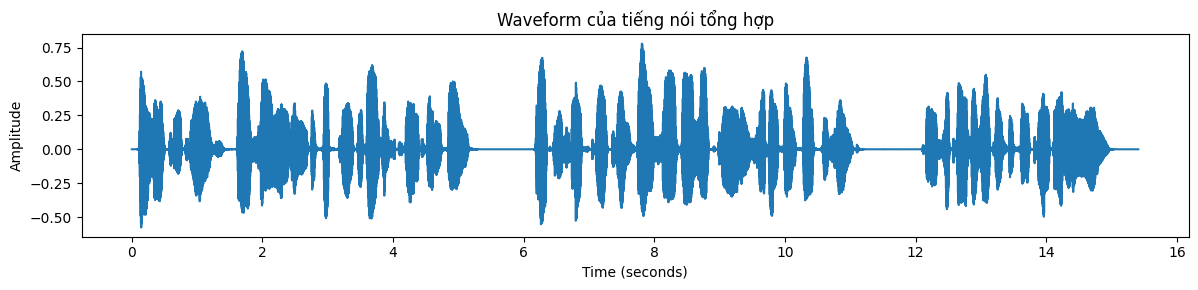

In [14]:
if audio_path.exists():
    import librosa
    y, sr = librosa.load(str(audio_path), sr=None, mono=True)
    duration_sec = len(y) / sr
    print(f"Sample rate: {sr} Hz")
    print(f"Duration: {duration_sec:.2f} s")
    print(f"Peak amplitude: {np.max(np.abs(y)):.4f}")
    plt.figure(figsize=(12, 3))
    times = np.arange(len(y)) / sr
    plt.plot(times, y)
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.title("Waveform của tiếng nói tổng hợp")
    plt.tight_layout()
    plt.show()
else:
    print("Bỏ qua phân tích audio vì chưa có file.")

# Bước 4 – Đánh giá chất lượng TTS

Chương 4 phân biệt đánh giá khách quan và chủ quan. Những chỉ số như MCD, F0 RMSE và Duration RMSE cần **audio tổng hợp và audio tham chiếu có căn chỉnh/định nghĩa thống nhất**; không thể tính đúng chỉ từ một file TTS đơn lẻ. MOS cần người nghe chấm theo thang 1–5; DRT/MRT kiểm tra khả năng phân biệt âm vị/từ; SUS dùng câu khó đoán về ngữ nghĩa để giảm tác động của kỳ vọng người nghe.

In [15]:
# Checklist đánh giá chủ quan: người đánh giá có thể điền sau khi nghe.
evaluation_form = pd.DataFrame([
    {"criterion": "Intelligibility / độ dễ hiểu", "score_1_to_5": None, "notes": ""},
    {"criterion": "Naturalness / độ tự nhiên", "score_1_to_5": None, "notes": ""},
    {"criterion": "Pronunciation / độ chính xác phát âm", "score_1_to_5": None, "notes": ""},
    {"criterion": "Prosody / ngữ điệu và ngắt nghỉ", "score_1_to_5": None, "notes": ""},
])
evaluation_form

,criterion,score_1_to_5,notes
0,Intelligibility / độ dễ hiểu,None,
1,Naturalness / độ tự nhiên,None,
2,Pronunciation / độ chính xác phát âm,None,
3,Prosody / ngữ điệu và ngắt nghỉ,None,


In [16]:
# Chỉ tính MOS khi có nhiều người đánh giá; đây là ví dụ nhập điểm giả lập.
# Thay bằng điểm thực tế, không dùng điểm giả lập làm kết quả nghiên cứu.
example_ratings = [4, 4, 3, 5, 4]
print("MOS minh họa =", round(float(np.mean(example_ratings)), 2), "/ 5")
print("Lưu ý: đây chỉ là ví dụ tính trung bình, không phải đánh giá audio ở trên.")

MOS minh họa = 4.0 / 5
Lưu ý: đây chỉ là ví dụ tính trung bình, không phải đánh giá audio ở trên.


## 10. Kiểm thử nhanh và lưu kết quả

Kiểm thử giúp phát hiện lỗi ở front-end trước khi chuyển sang tổng hợp. Đây là kiểm thử đơn giản, không phải đánh giá chất lượng ngôn ngữ toàn diện.

In [17]:
# Các bất biến cơ bản
assert isinstance(normalized_text, str) and len(normalized_text) > 0
assert isinstance(structure, list) and len(structure) > 0
assert all("text" in item and "pause_after_ms" in item for item in prosody)
print("Các kiểm thử cấu trúc cơ bản: PASS")

Các kiểm thử cấu trúc cơ bản: PASS


In [18]:
# Lưu cấu trúc front-end và prosody để xem lại/đưa vào pipeline khác.
with open(output_dir / "front_end_analysis.json", "w", encoding="utf-8") as f:
    json.dump(front_end, f, ensure_ascii=False, indent=2)
with open(output_dir / "prosody_markup.json", "w", encoding="utf-8") as f:
    json.dump(prosody, f, ensure_ascii=False, indent=2)
print("Đã lưu JSON vào", output_dir.resolve())

Đã lưu JSON vào D:\audio & speech\TH\TH_TrenLop\tts_outputs


## 11. Tổng kết luồng

`Raw text → Document structure → Text normalization → POS/homograph analysis → Lexicon/G2P → Prosody markup → TTS engine → Evaluation`

### Hạn chế cần nêu khi báo cáo
- Bộ TN hiện tại là heuristic tiếng Anh, chưa phù hợp dùng trực tiếp cho tiếng Việt.
- CMUdict là từ điển phát âm tiếng Anh; muốn làm tiếng Việt cần từ điển/phonemizer tiếng Việt.
- POS và quy tắc `record` chỉ minh họa nhập nhằng; không phải bộ khử nhập nhằng tổng quát.
- Prosody markup mới mô hình hóa ngắt nghỉ; chưa sinh ToBI/Fujisaki, F0 contour hay duration âm vị.
- gTTS là backend tiện cho demo; chưa phải tự triển khai Klatt, unit selection, HMM-TTS hoặc neural vocoder.
- Chương 14 là front-end phân tích văn bản/ngữ âm; Chương 4 PDF của bạn là roadmap rộng hơn bao gồm prosody, synthesis và evaluation.